In [1]:
import matplotlib.pyplot as plt
import numpy as np
from simulate_bounds import EPS_INTERVAL, IMPORTANT_MODES, MODE_DEGREE

from rayfish.classical_fisher_information.measurement_basis.hermite_gaussian_basis import (  # noqa: E501
    _mix_modes_via_unitary,
    measurement_basis,
)
from rayfish.visualize_helpers import (
    draw_fi_curves,
    fi_legend_handles,
    latexify,
    plot_fi_comparison,
    plot_mode_mixing_sweep,
)

latexify()
FORMAT = "pdf"
continuous_cmaps = [
    "Greens",
    "Reds",
    "Purples",
    "Oranges",
    "Blues",
    "plasma",
    "viridis",
    "cividis",
    "magma",
    "inferno",
    "turbo",
    "pink",
    "bone",
    "gray",
    "copper",
]

In [2]:
%matplotlib inline

In [3]:
selected_eps = EPS_INTERVAL[:-1]

# Mode leakage

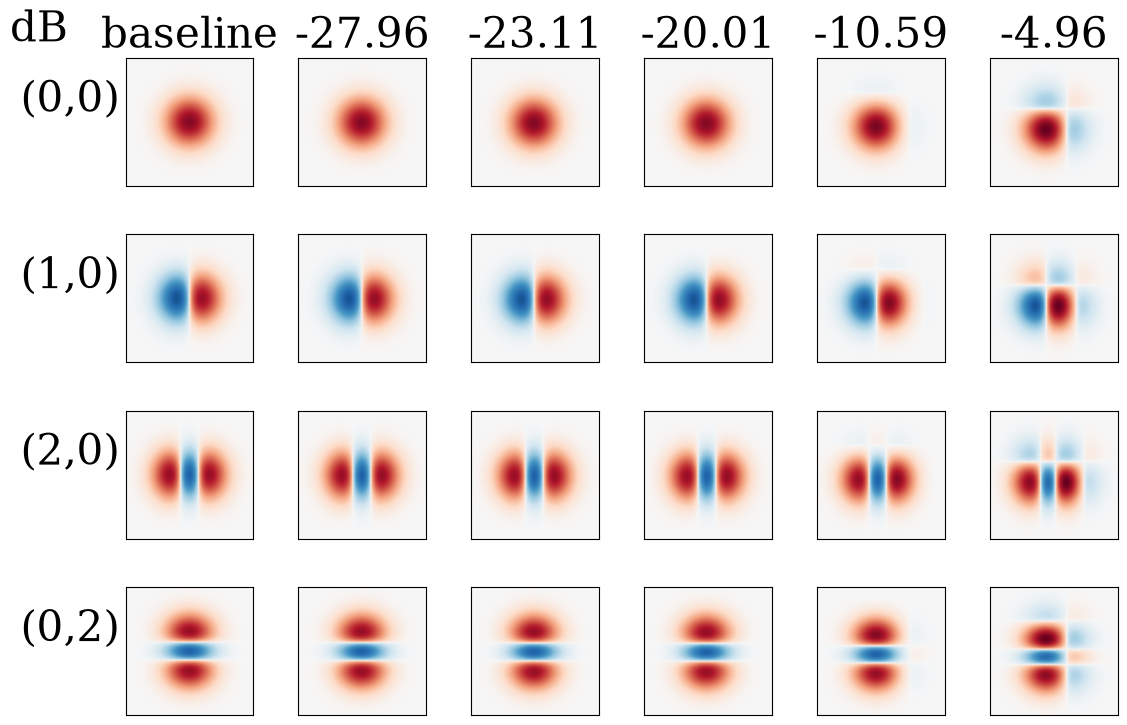

In [4]:
fig, _ = plot_mode_mixing_sweep(
    measurement_basis(MODE_DEGREE),
    selected_eps,
    _mix_modes_via_unitary,
    mode_degree=MODE_DEGREE,
    mode_indices=[i * MODE_DEGREE + j for (i, j) in IMPORTANT_MODES],
)

fig.savefig(
    f"mixed_modes.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

# Load data

In [5]:
coords = np.load("coordinates.npy")
p_range = -coords[0, :, 6]
x_range = coords[:, 0, 2]

fis = []
fis_inv = []
for mixing_eps in selected_eps:
    fis.append(np.load(f"fi_ms_eps_{mixing_eps:.2f}.npy"))
    fis_inv.append(np.load(f"fi_ms_inv_eps_{mixing_eps:.2f}.npy"))

# s param

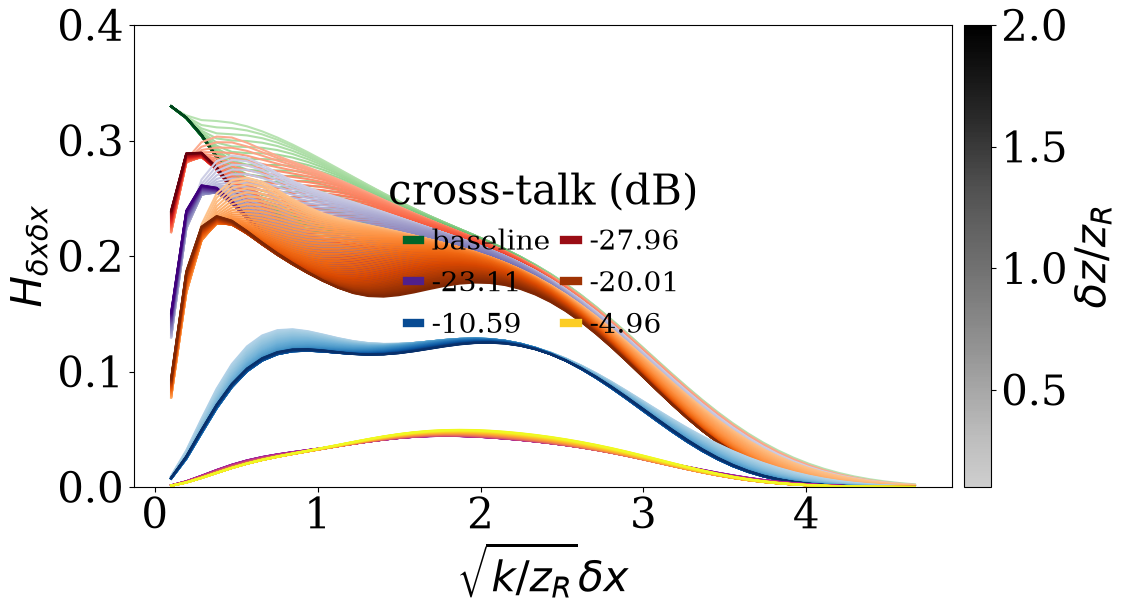

In [6]:
fig, axs = plot_fi_comparison(
    [np.sum(fi, axis=2)[:, :, 0, 0] for fi in fis],
    x_range,
    p_range,
    selected_eps,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\sqrt{k/z_R} \delta x$",
    ylabel=r"$H_{\delta x \delta x}$",
    gradient_label=r"$\delta z / z_R$",
    ylim=(0, 0.4),
)

fig.savefig(
    f"s_param_fi_mixing.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

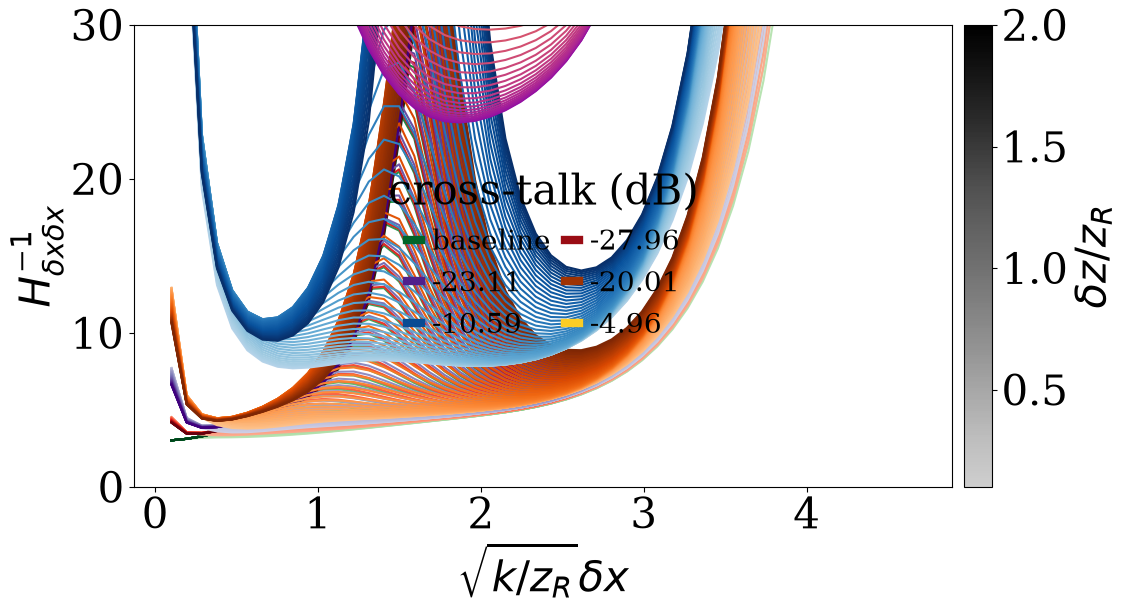

In [7]:
fig, axs = plot_fi_comparison(
    [fi_inv[:, :, 0, 0] for fi_inv in fis_inv],
    x_range,
    p_range,
    selected_eps,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\sqrt{k/z_R} \delta x$",
    ylabel=r"$H^{-1}_{\delta x \delta x}$",
    gradient_label=r"$\delta z / z_R$",
    ylim=(0, 30),
)

fig.savefig(
    f"s_param_crb_mixing.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

# p param

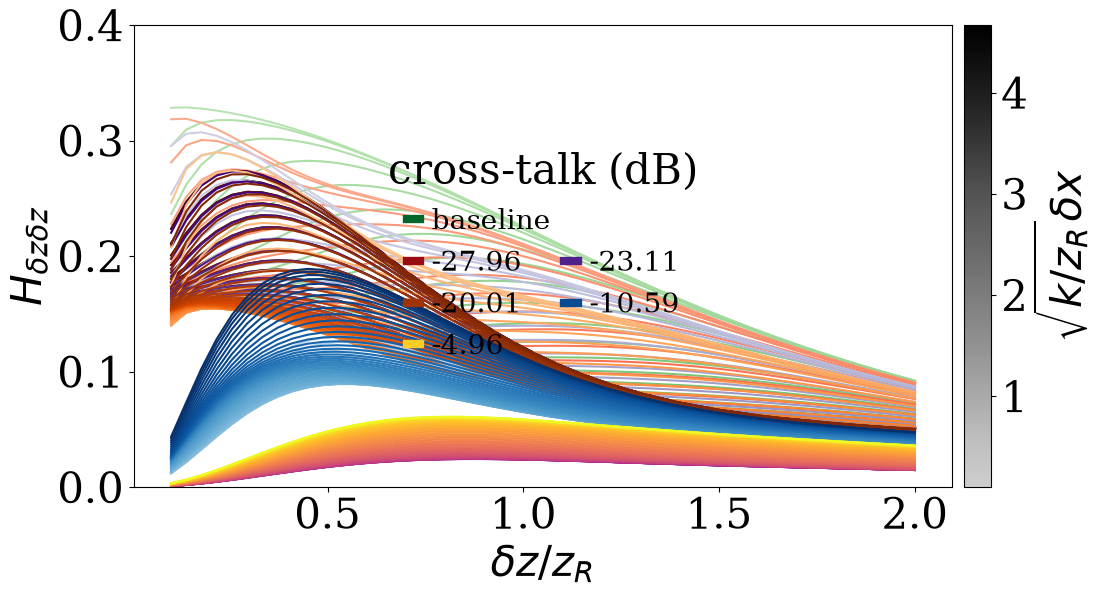

In [8]:
fig, axs = plot_fi_comparison(
    [np.transpose(np.sum(fi, axis=2)[:, :, 1, 1]) for fi in fis],
    p_range,
    x_range,
    selected_eps,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R} \delta x$",
    ylim=(0, 0.4),
    baseline_first=True,
)

fig.savefig(
    f"p_param_fi_mixing.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

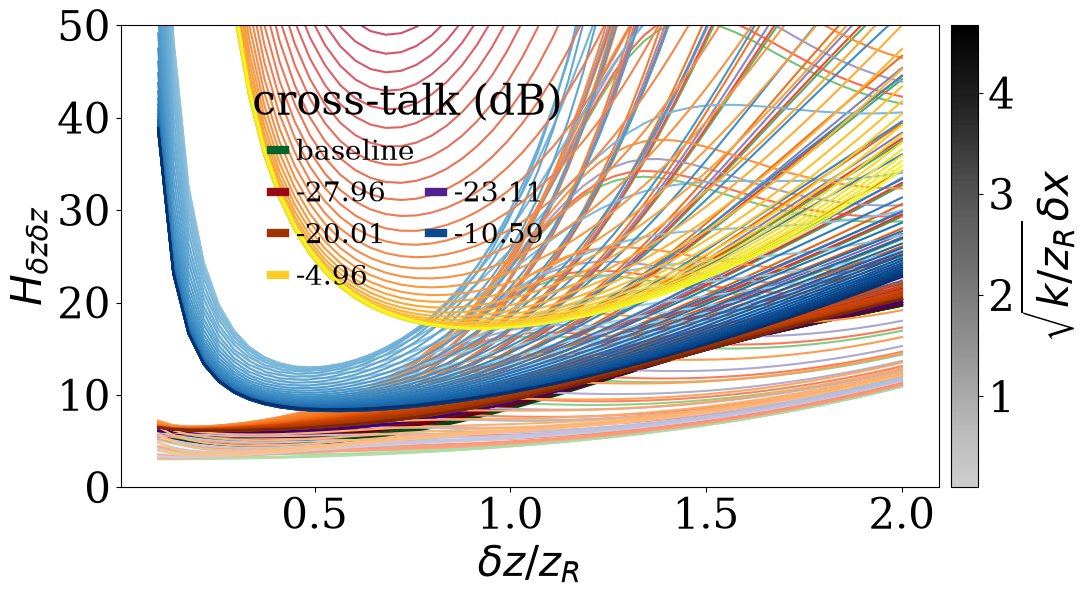

In [9]:
fig, axs = plot_fi_comparison(
    [np.transpose(fi_inv[:, :, 1, 1]) for fi_inv in fis_inv],
    p_range,
    x_range,
    selected_eps,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R} \delta x$",
    ylim=(0, 50),
    baseline_first=True,
)

leg = axs[0].get_legend()
handles = leg.legend_handles  # type: ignore
labels = [t.get_text() for t in leg.get_texts()]  # type: ignore
title = leg.get_title().get_text()  # type: ignore

axs[0].legend(
    handles=handles,
    labels=labels,
    title=title,
    frameon=False,
    ncol=2,
    handlelength=0.5,
    handletextpad=0.4,
    columnspacing=0.5,
    loc="center",
    bbox_to_anchor=(0.35, 0.65),
)

fig.savefig(
    f"p_param_crb_mixing.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

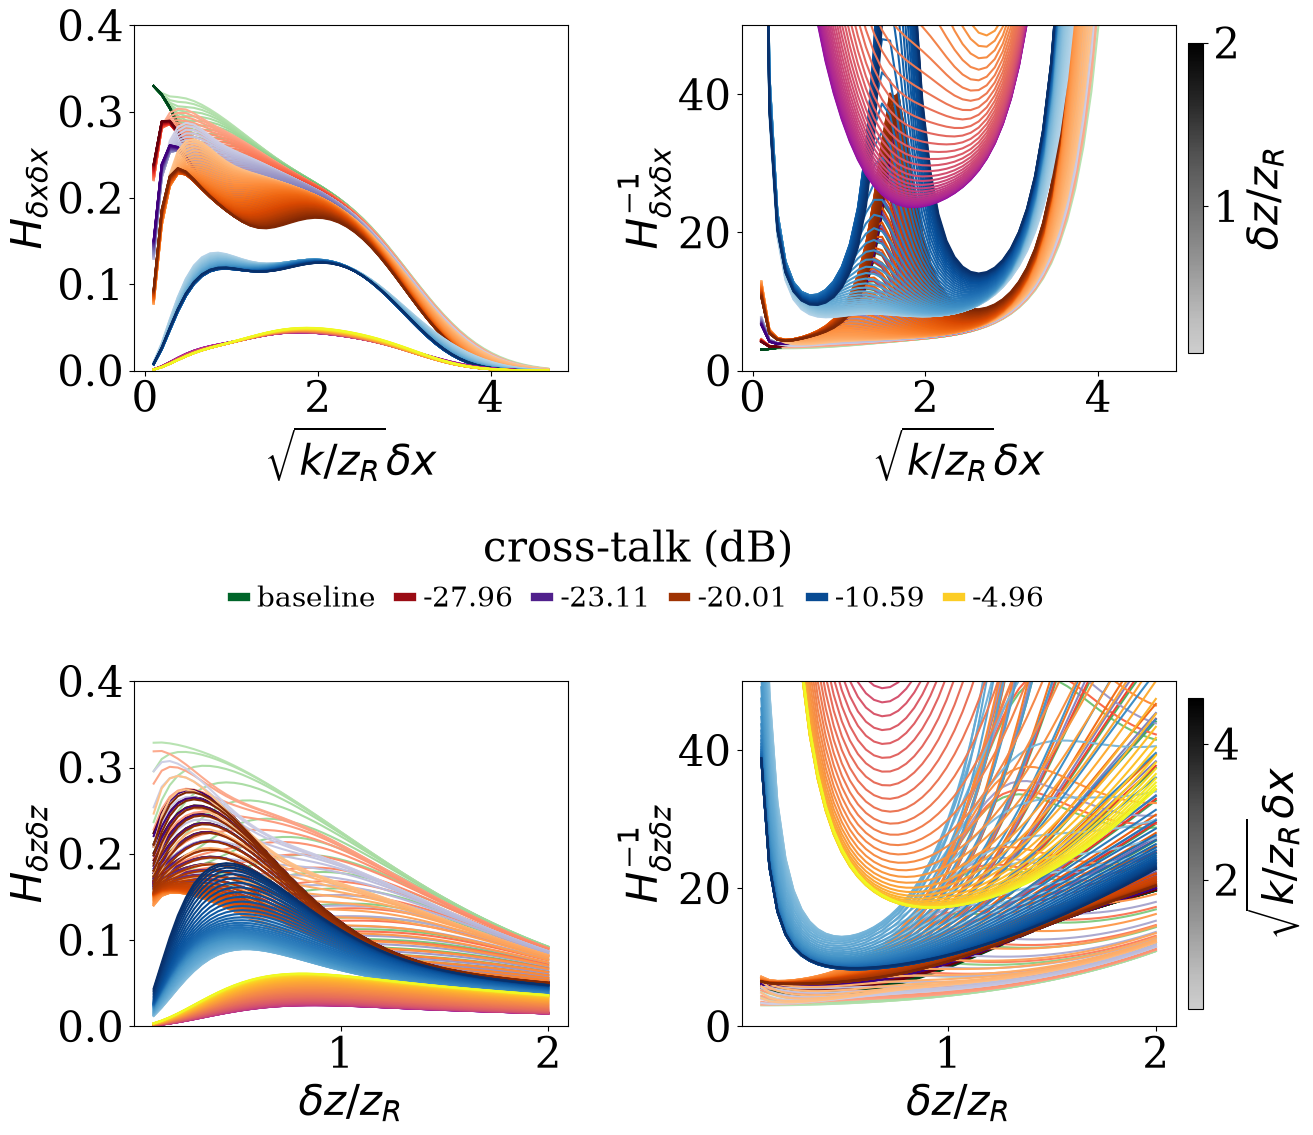

In [10]:
# Combined 2x2 grid: FI (left column) and Cramer-Rao bound (CRB = inverse FI,
# right column), for the transverse (s, top row) and depth (p, bottom row)
# coordinates. The cross-talk colour legend is shared by all four panels
# (colours never change) and sits in the band between the rows; each row gets
# its own gradient colorbar on the far right -- the s-row gradient runs over
# delta z, the p-row gradient over delta x.
fig = plt.figure(figsize=(16, 13))
gs = fig.add_gridspec(2, 2, hspace=0.90, wspace=0.40)
axs = np.array([[fig.add_subplot(gs[i, j]) for j in range(2)] for i in range(2)])

# top row (s / transverse): x-axis = delta x, gradient over delta z
sm_s = draw_fi_curves(
    axs[0, 0],
    [np.sum(fi, axis=2)[:, :, 0, 0] for fi in fis],
    x_range,
    p_range,
    len(selected_eps),
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\sqrt{k/z_R} \delta x$",
    ylabel=r"$H_{\delta x \delta x}$",
    ylim=(0, 0.4),
)
draw_fi_curves(
    axs[0, 1],
    [fi_inv[:, :, 0, 0] for fi_inv in fis_inv],
    x_range,
    p_range,
    len(selected_eps),
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\sqrt{k/z_R} \delta x$",
    ylabel=r"$H^{-1}_{\delta x \delta x}$",
    ylim=(0, 50),
)

# bottom row (p / depth): x-axis = delta z, gradient over delta x
sm_p = draw_fi_curves(
    axs[1, 0],
    [np.transpose(np.sum(fi, axis=2)[:, :, 1, 1]) for fi in fis],
    p_range,
    x_range,
    len(selected_eps),
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
    ylim=(0, 0.4),
)
draw_fi_curves(
    axs[1, 1],
    [np.transpose(fi_inv[:, :, 1, 1]) for fi_inv in fis_inv],
    p_range,
    x_range,
    len(selected_eps),
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H^{-1}_{\delta z \delta z}$",
    ylim=(0, 50),
)

# one gradient colorbar per coordinate system, on the far right of its row
fig.colorbar(
    sm_s,
    ax=axs[0, :],
    location="right",
    shrink=0.9,
    pad=0.01,
    label=r"$\delta z / z_R$",
)
fig.colorbar(
    sm_p,
    ax=axs[1, :],
    location="right",
    shrink=0.9,
    pad=0.01,
    label=r"$\sqrt{k/z_R} \delta x$",
)

# one cross-talk legend for all four panels, centered in the band between rows
fig.legend(
    handles=fi_legend_handles(
        selected_eps, cmaps=continuous_cmaps[: len(fis)], legend_ncol=6
    ),
    title="cross-talk (dB)",
    frameon=False,
    loc="center",
    bbox_to_anchor=(0.44, 0.46),
    ncol=6,
    handlelength=0.5,
    handletextpad=0.4,
    columnspacing=0.8,
)

fig.savefig(
    f"combined_fi_crb_mixing.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()